# 01 · Data exploration: importing, standardising and exploring Serie A data

**Goal of this notebook:** turn 34 seasons of raw Serie A results from
[Football-Data.co.uk](https://www.football-data.co.uk/italym.php) into one clean,
consistent dataset that the rest of the project can rely on, then explore it to
find the patterns that matter for predicting results (section 6).

The pipeline logic lives in `src/` so it can be tested and reused; this notebook
calls those functions and shows *why* each step is needed.

| Step | Code |
|---|---|
| Download the raw season files | `src/data_loader.py` (`python -m src.data_loader`) |
| Read, standardise, combine and validate | `src/preprocessing.py` (`python -m src.preprocessing`) |

In [1]:
import csv
import io

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from src.config import FIGURES_DIR, RAW_DATA_DIR
from src.data_loader import season_label
from src.preprocessing import (
    COLUMN_SOURCES,
    build_matches,
    read_raw_season,
    save_matches,
    season_files,
    season_summary,
    validate_matches,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

## 1. The raw files

One CSV per season, named `I1_<season code>.csv` (`I1` is Football-Data's code for Serie A).
The files were collected over 30+ years, and their format changed a lot over that time.

In [2]:
def season_of(path):
    return season_label(path.stem.split("_")[1])


raw_overview = pd.DataFrame(
    [
        {
            "season": season_of(path),
            "file": path.name,
            "size_kb": round(path.stat().st_size / 1024, 1),
            "columns": read_raw_season(path).shape[1],
            "matches": read_raw_season(path).shape[0],
        }
        for path in season_files()
    ]
).set_index("season")

print(f"{len(raw_overview)} season files, {raw_overview['matches'].sum():,} matches in total")
raw_overview

34 season files, 11,826 matches in total


,file,size_kb,columns,matches
season,,,,
1993-94,I1_9394.csv,12.5,7,306
1994-95,I1_9495.csv,23.4,7,306
1995-96,I1_9596.csv,14.9,10,306
1996-97,I1_9697.csv,15.0,10,306
1997-98,I1_9798.csv,12.1,10,306
1998-99,I1_9899.csv,12.4,10,306
1999-00,I1_9900.csv,14.7,10,306
2000-01,I1_0001.csv,29.1,25,306
2001-02,I1_0102.csv,31.0,28,306


The number of columns grows from about 10 in the 1990s to over 100 today, as Football-Data added
match statistics (shots, corners, cards) and odds from more and more bookmakers.
Getting from this to one table needs four fixes.

### Quirk 1: ragged rows

In some older files, rows have **more or fewer fields than the header**. Read naively with
`pd.read_csv`, those rows cause errors or get skipped, and matches are silently lost:

In [3]:
for code in ["0304", "0405"]:
    path = RAW_DATA_DIR / f"I1_{code}.csv"
    naive = pd.read_csv(path, on_bad_lines="skip").dropna(how="all")
    robust = read_raw_season(path)
    print(f"{season_label(code)}: naive pd.read_csv -> {len(naive)} matches, "
          f"read_raw_season -> {len(robust)} matches")

2003-04: naive pd.read_csv -> 194 matches, read_raw_season -> 306 matches
2004-05: naive pd.read_csv -> 300 matches, read_raw_season -> 380 matches


In [4]:
# The field count of each row in the 2003-04 file, compared with its header
with open(RAW_DATA_DIR / "I1_0304.csv", encoding="utf-8") as f:
    rows = list(csv.reader(f))
header_width = len(rows[0])
row_widths = pd.Series([len(r) for r in rows[1:]]).value_counts().sort_index()
print(f"Header has {header_width} fields; rows have:")
print(row_widths.rename("rows").to_string())

Header has 45 fields; rows have:
44    112
45     82
46     32
49     32
50     32
51     16


Checking the files shows the extra fields are **always empty**: the data still lines up with the
header. `read_raw_season` therefore reads with Python's `csv` module, pads or trims every row
to the header length, and raises an error if a row ever has real data past the last column.

### Quirk 2: two date formats

Up to 2017-18 dates are `dd/mm/yy`; from 2018-19 they are `dd/mm/yyyy`.

In [5]:
for code in ["1718", "1819"]:
    dates = read_raw_season(RAW_DATA_DIR / f"I1_{code}.csv")["Date"]
    print(f"{season_label(code)}: {dates.head(3).tolist()}")

2017-18: ['19/08/17', '19/08/17', '20/08/17']
2018-19: ['18/08/2018', '18/08/2018', '19/08/2018']


### Quirk 3: renamed columns

The same information sometimes appears under different names. The market-average odds were
`BbAvH` / `BbAvD` / `BbAvA` (from the BetBrain site) until 2018-19, then `AvgH` / `AvgD` / `AvgA`.

In [6]:
columns_by_season = {season_of(p): set(read_raw_season(p).columns) for p in season_files()}
renamed = pd.DataFrame(
    {name: {s: name in cols for s, cols in columns_by_season.items()} for name in ["BbAvH", "AvgH"]}
)
renamed[renamed.any(axis=1)].T

,2005-06,2006-07,2007-08,2008-09,2009-10,2010-11,2011-12,2012-13,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
BbAvH,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False,False,False
AvgH,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,True,True,True,True,True


### Quirk 4: byte-order mark

Files from 2024-25 onwards start with an invisible UTF-8 byte-order mark (BOM). Without handling it,
the first column would be called `'\ufeffDiv'` instead of `'Div'`.

In [7]:
print((RAW_DATA_DIR / "I1_2425.csv").read_bytes()[:12])

b'\xef\xbb\xbfDiv,Date,'


## 2. Standardising into one schema

`standardise_season` maps every raw file onto the same columns with clear snake_case names.
Where Football-Data used several names for the same thing, the first available one is used.
Columns a season doesn't have (e.g. shots before 2005-06) are kept as missing values, so every
season has the same shape.

In [8]:
mapping = pd.DataFrame(
    [(name, " / ".join(sources)) for name, sources in COLUMN_SOURCES.items()],
    columns=["standard column", "raw Football-Data column(s)"],
)
mapping

,standard column,raw Football-Data column(s)
0,date,Date
1,time,Time
2,home_team,HomeTeam
3,away_team,AwayTeam
4,home_goals,FTHG / HG
5,away_goals,FTAG / AG
6,result,FTR / Res
7,ht_home_goals,HTHG
8,ht_away_goals,HTAG
9,ht_result,HTR


In [9]:
matches = build_matches()
print(f"{len(matches):,} matches x {matches.shape[1]} columns")
matches.head()

11,826 matches x 31 columns


,season,season_start,date,time,home_team,away_team,home_goals,away_goals,result,ht_home_goals,ht_away_goals,ht_result,referee,home_shots,away_shots,home_shots_on_target,away_shots_on_target,home_fouls,away_fouls,home_corners,away_corners,home_yellow_cards,away_yellow_cards,home_red_cards,away_red_cards,b365_home,b365_draw,b365_away,avg_odds_home,avg_odds_draw,avg_odds_away
0,1993-94,1993,1993-08-29,<NA>,Atalanta,Cagliari,5,2,H,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,1993-94,1993,1993-08-29,<NA>,Genoa,Roma,2,0,H,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,1993-94,1993,1993-08-29,<NA>,Inter,Reggiana,2,1,H,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,1993-94,1993,1993-08-29,<NA>,Juventus,Cremonese,1,0,H,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,1993-94,1993,1993-08-29,<NA>,Lazio,Foggia,0,0,D,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [10]:
matches.dtypes.to_frame("dtype").T

,season,season_start,date,time,home_team,away_team,home_goals,away_goals,result,ht_home_goals,ht_away_goals,ht_result,referee,home_shots,away_shots,home_shots_on_target,away_shots_on_target,home_fouls,away_fouls,home_corners,away_corners,home_yellow_cards,away_yellow_cards,home_red_cards,away_red_cards,b365_home,b365_draw,b365_away,avg_odds_home,avg_odds_draw,avg_odds_away
dtype,string,int64,datetime64[ns],string,string,string,Int64,Int64,string,Int64,Int64,string,string,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64


Goals and statistics use pandas' nullable `Int64` type, so a missing value (e.g. no shot data in
1995) stays *missing* instead of turning the whole column into floats or being filled with 0.
Odds are decimal (European) odds as `Float64`.

## 3. Validation

`validate_matches` checks the combined data before it is saved. It returns a list of problems,
and the script refuses to save if the list isn't empty. It checks that:

- no required field (season, date, teams, goals, result) is missing
- the result (`H` / `D` / `A`) agrees with the score, at full time and at half time
- no team plays itself, and no fixture appears twice in a season
- every date falls inside its season
- there are no negative counts and no odds of 1.0 or lower
- every completed season has `n × (n − 1)` matches, because each team hosts every other team once

In [11]:
issues = validate_matches(matches)
print("No issues found" if not issues else "\n".join(issues))

No issues found


In [12]:
summary = season_summary(matches)
summary

,teams,matches,first_match,last_match
season,,,,
1993-94,18,306,1993-08-29,1994-05-01
1994-95,18,306,1994-09-04,1995-06-04
1995-96,18,306,1995-08-27,1996-05-12
1996-97,18,306,1996-09-08,1997-06-01
1997-98,18,306,1997-08-31,1998-05-16
1998-99,18,306,1998-09-12,1999-05-23
1999-00,18,306,1999-08-28,2000-05-14
2000-01,18,306,2000-09-30,2001-06-17
2001-02,18,306,2001-08-25,2002-05-05


Serie A had **18 teams (306 matches)** up to 2003-04 and **20 teams (380 matches)** from 2004-05.
The 2026-27 season is still in progress, so it is excluded from the completeness check.
The 2019-20 season ran until August 2020 because of the COVID-19 break.

## 4. Which data is available in each season?

Results are available for all 34 seasons, but statistics and betting odds start later. This
determines which seasons each kind of model can be trained on.

In [13]:
coverage_groups = {
    "Full-time result": ["home_goals", "away_goals", "result"],
    "Half-time score": ["ht_home_goals", "ht_away_goals"],
    "Bet365 odds": ["b365_home", "b365_draw", "b365_away"],
    "Market-average odds": ["avg_odds_home", "avg_odds_draw", "avg_odds_away"],
    "Match statistics": [c for c in matches.columns if c.endswith(("shots", "shots_on_target", "fouls", "corners", "cards"))],
    "Kick-off time": ["time"],
    "Referee": ["referee"],
}

coverage = pd.DataFrame(
    {
        group: matches[cols].notna().all(axis=1).groupby(matches["season"]).mean()
        for group, cols in coverage_groups.items()
    }
).T  # rows = data group, columns = season

# Table view of the chart below: share of matches with the data (1.0 = all matches)
coverage.round(2)

season,1993-94,1994-95,1995-96,1996-97,1997-98,1998-99,1999-00,2000-01,2001-02,2002-03,2003-04,2004-05,2005-06,2006-07,2007-08,2008-09,2009-10,2010-11,2011-12,2012-13,2013-14,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
Full-time result,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0
Half-time score,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0
Bet365 odds,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.99,0.92,0.98,0.99,1.0,1.0,1.0,1.0,0.99,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.99,1.0,1.0,1.0,1.0,1.0,1.0
Market-average odds,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,1.00,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0
Match statistics,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.96,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0
Kick-off time,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.00,1.0,1.0,1.0,1.0,1.0,1.0
Referee,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,1.00,1.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0


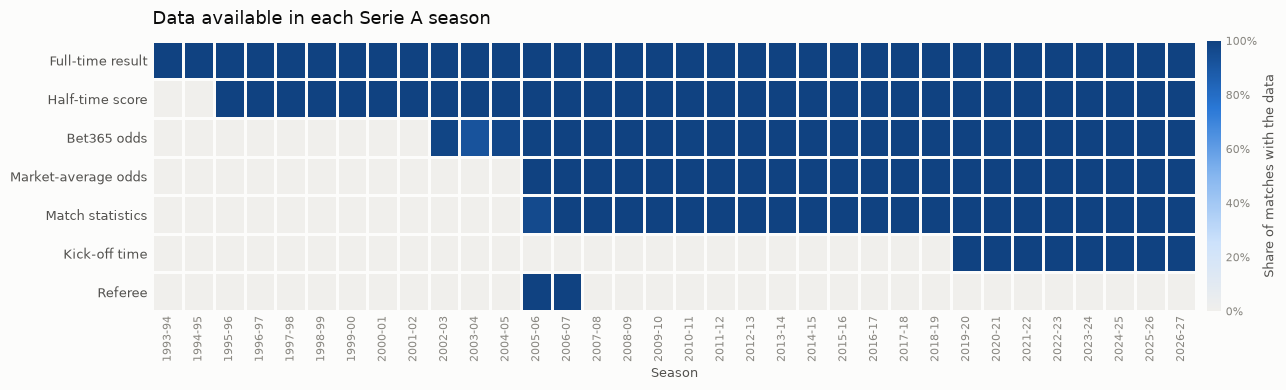

In [14]:
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
# Sequential single-hue ramp (light = no data, dark blue = every match has it)
coverage_cmap = LinearSegmentedColormap.from_list(
    "coverage", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"]
)

fig, ax = plt.subplots(figsize=(13, 4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
mesh = ax.pcolormesh(coverage.values, cmap=coverage_cmap, vmin=0, vmax=1,
                     edgecolors=SURFACE, linewidth=2)

ax.set_xticks([i + 0.5 for i in range(coverage.shape[1])],
              coverage.columns, rotation=90, fontsize=8, color=MUTED)
ax.set_yticks([i + 0.5 for i in range(coverage.shape[0])],
              coverage.index, fontsize=9, color=INK_2)
ax.invert_yaxis()
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title("Data available in each Serie A season", loc="left", fontsize=13, color=INK, pad=12)
ax.set_xlabel("Season", color=INK_2, fontsize=9)

cbar = fig.colorbar(mesh, ax=ax, fraction=0.025, pad=0.01)
cbar.set_label("Share of matches with the data", color=INK_2, fontsize=9)
cbar.ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
cbar.ax.tick_params(colors=MUTED, labelsize=8, length=0)
cbar.outline.set_visible(False)

fig.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES_DIR / "01_data_coverage_by_season.png", dpi=150, facecolor=SURFACE)
plt.show()

In [15]:
first_full_season = {
    group: (row[row >= 0.99].index[0] if (row >= 0.99).any() else "never complete")
    for group, row in coverage.iterrows()
}
pd.Series(first_full_season, name="first season with complete data").to_frame()

,first season with complete data
Full-time result,1993-94
Half-time score,1995-96
Bet365 odds,2005-06
Market-average odds,2005-06
Match statistics,2006-07
Kick-off time,2019-20
Referee,2005-06


**What this means for modelling:**

- **Results-only features** (form, goals scored and conceded, points, head-to-head) can use all
  34 seasons, roughly 11,800 matches.
- **Match statistics** (shots, corners, cards) only exist from **2005-06**, so models using them
  are limited to about 8,000 matches.
- **Betting odds** make a strong benchmark: the bookmakers' implied probabilities are what our
  models have to beat. Bet365 odds go back to 2002-03 and market averages to 2005-06.
- Referee and kick-off time are too sparse to be useful features.

## 5. Save the processed dataset

In [16]:
path = save_matches(matches)
print(f"Saved {len(matches):,} matches to {path.relative_to(path.parents[2])}")

Saved 11,826 matches to data\processed\matches.csv


## 6. Exploratory data analysis

From here on, the notebook works only from the saved file `data/processed/matches.csv`,
loaded with `load_matches()`. This is exactly what the modelling steps will use.

The 2026-27 season is still in progress (only part of its 380 matches have been played), so
**per-season trends use completed seasons only**. Overall totals include every match.

In [17]:
import numpy as np
from scipy.stats import poisson

from src.preprocessing import load_matches

matches = load_matches()
latest_season_start = matches["season_start"].max()
completed = matches[matches["season_start"] < latest_season_start].copy()
seasons = completed["season"].unique().tolist()

print(f"All matches: {len(matches):,} | completed seasons: {len(seasons)} "
      f"({seasons[0]} to {seasons[-1]}), {len(completed):,} matches")

# --- Chart style -------------------------------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SHADE = "#e1e0d9", "#c3c2b7", "#f0efec"
BLUE, BLUE_LIGHT, AQUA, ORANGE = "#2a78d6", "#86b6ef", "#1baf7a", "#eb6834"

OUTCOMES = ["H", "D", "A"]
OUTCOME_LABELS = {"H": "Home win", "D": "Draw", "A": "Away win"}
OUTCOME_COLORS = {"H": BLUE, "D": AQUA, "A": ORANGE}


def style_axes(ax, grid="y"):
    """Quiet axes: no box, light gridlines, muted tick labels."""
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None):
    ax.set_title(title, loc="left", fontsize=12, color=INK, pad=22 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def season_axis(ax):
    ax.set_xticks(range(len(seasons)), seasons, rotation=90)
    ax.set_xlim(-0.6, len(seasons) - 0.4)


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")

All matches: 11,826 | completed seasons: 33 (1993-94 to 2025-26), 11,726 matches


### 6.1 Match outcomes

What we are predicting: the full-time result, home win (`H`), draw (`D`) or away win (`A`).

In [18]:
outcome_share = matches["result"].value_counts(normalize=True).reindex(OUTCOMES)
scoreline = (matches["home_goals"].astype(str) + "-" + matches["away_goals"].astype(str))
top_scores = scoreline.value_counts(normalize=True).head(5)

display(pd.DataFrame({"share": outcome_share.round(3)}, index=OUTCOMES)
        .rename(index=OUTCOME_LABELS))
print("Most common scorelines:", ", ".join(f"{s} ({p:.1%})" for s, p in top_scores.items()))

,share
Home win,0.454
Draw,0.273
Away win,0.273


Most common scorelines: 1-1 (12.5%), 1-0 (10.5%), 2-1 (9.1%), 0-0 (8.1%), 2-0 (7.9%)


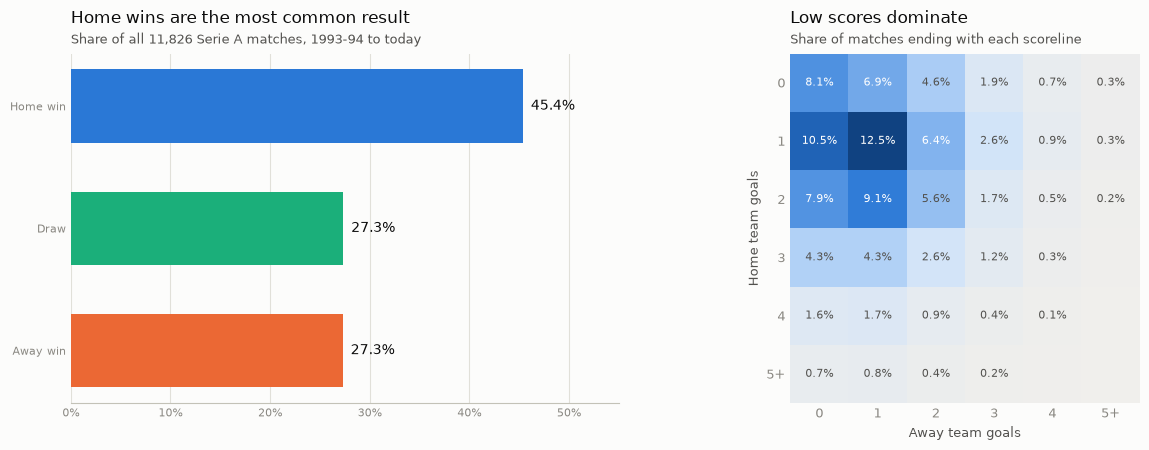

In [19]:
fig, (ax_bar, ax_heat) = plt.subplots(
    1, 2, figsize=(13, 4.6), facecolor=SURFACE, gridspec_kw={"width_ratios": [1, 1.15]}
)

# Left: share of each outcome
y = range(len(OUTCOMES))[::-1]
ax_bar.barh(y, outcome_share.values, color=[OUTCOME_COLORS[o] for o in OUTCOMES], height=0.6)
for yi, share in zip(y, outcome_share.values):
    ax_bar.text(share + 0.008, yi, f"{share:.1%}", va="center", fontsize=10, color=INK)
ax_bar.set_yticks(list(y), [OUTCOME_LABELS[o] for o in OUTCOMES], fontsize=10, color=INK_2)
ax_bar.set_xlim(0, 0.55)
ax_bar.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
style_axes(ax_bar, grid="x")
set_title(ax_bar, "Home wins are the most common result",
          f"Share of all {len(matches):,} Serie A matches, 1993-94 to today")

# Right: how often each scoreline occurs (5+ goals grouped)
cap = 5
grid_counts = pd.crosstab(
    matches["home_goals"].clip(upper=cap), matches["away_goals"].clip(upper=cap), normalize=True
).reindex(index=range(cap + 1), columns=range(cap + 1), fill_value=0)
seq_cmap = LinearSegmentedColormap.from_list(
    "seq", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"]
)
ax_heat.imshow(grid_counts.values, cmap=seq_cmap, vmin=0, vmax=grid_counts.values.max())
for i in range(cap + 1):
    for j in range(cap + 1):
        share = grid_counts.iloc[i, j]
        if share >= 0.001:
            ax_heat.text(j, i, f"{share:.1%}", ha="center", va="center", fontsize=8,
                         color="#ffffff" if share > 0.06 else INK_2)
labels = [str(n) for n in range(cap)] + [f"{cap}+"]
ax_heat.set_xticks(range(cap + 1), labels)
ax_heat.set_yticks(range(cap + 1), labels)
ax_heat.set_xlabel("Away team goals", color=INK_2, fontsize=9)
ax_heat.set_ylabel("Home team goals", color=INK_2, fontsize=9)
ax_heat.tick_params(colors=MUTED, labelsize=9, length=0)
for spine in ax_heat.spines.values():
    spine.set_visible(False)
set_title(ax_heat, "Low scores dominate", "Share of matches ending with each scoreline")

fig.tight_layout(w_pad=4)
save_figure(fig, "02_outcome_distribution.png")
plt.show()

**Interpretation**

- Home wins happen in about **45%** of matches, while draws and away wins each happen in about
  **27%**. A naive model that *always predicts a home win* would therefore be right about 45% of
  the time. That is the **minimum accuracy our models must beat**.
- Draws are as common as away wins but are notoriously hard to predict, because they have no
  clear "favourite". We should expect the models to struggle most with this class.
- Matches are low scoring: **1-1, 1-0 and 2-1** are the most common scorelines, and a single goal
  often decides the result. This is a large part of why football is hard to predict.

### 6.2 Goals per match

In [20]:
total_goals = matches["home_goals"] + matches["away_goals"]
mean_goals, var_goals = float(total_goals.mean()), float(total_goals.var())
goals_by_season = (completed["home_goals"] + completed["away_goals"]).groupby(completed["season"]).mean()

print(f"Goals per match: mean {mean_goals:.2f}, variance {var_goals:.2f}")
print(f"Matches with 3+ goals (over 2.5): {(total_goals >= 3).mean():.1%}")
print(f"Lowest season: {goals_by_season.idxmin()} ({goals_by_season.min():.2f}), "
      f"highest: {goals_by_season.idxmax()} ({goals_by_season.max():.2f})")

Goals per match: mean 2.66, variance 2.74
Matches with 3+ goals (over 2.5): 49.5%
Lowest season: 1993-94 (2.42), highest: 2020-21 (3.05)


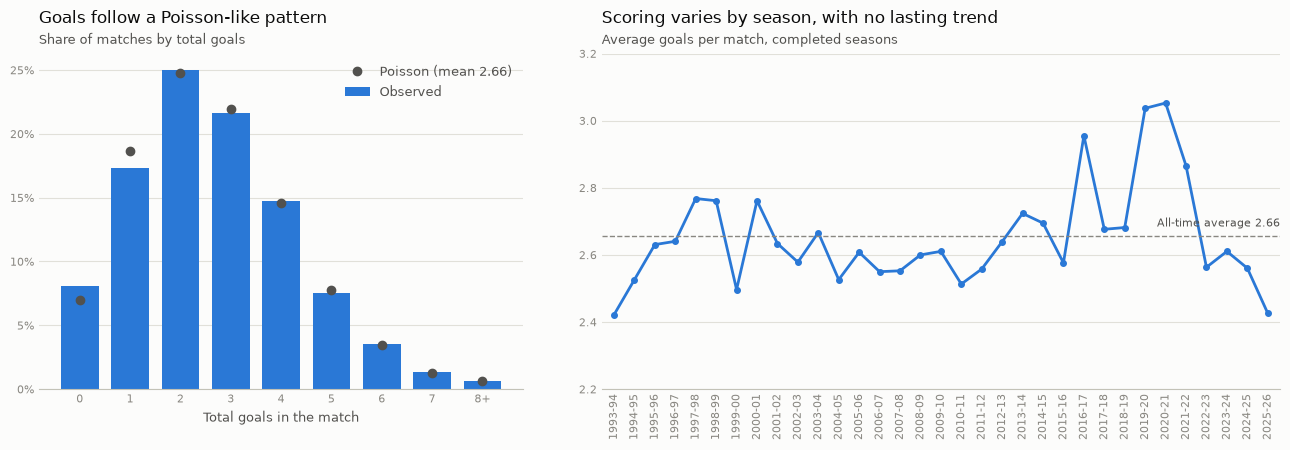

In [21]:
fig, (ax_hist, ax_trend) = plt.subplots(
    1, 2, figsize=(13, 4.6), facecolor=SURFACE, gridspec_kw={"width_ratios": [1, 1.4]}
)

# Left: distribution of total goals, compared with a Poisson distribution
cap = 8
observed = total_goals.clip(upper=cap).value_counts(normalize=True).reindex(range(cap + 1), fill_value=0)
expected = [poisson.pmf(k, mean_goals) for k in range(cap)] + [poisson.sf(cap - 1, mean_goals)]
ax_hist.bar(observed.index, observed.values, color=BLUE, width=0.75, label="Observed")
ax_hist.plot(observed.index, expected, "o", color=INK_2, markersize=6,
             label=f"Poisson (mean {mean_goals:.2f})")
ax_hist.set_xticks(range(cap + 1), [str(k) for k in range(cap)] + [f"{cap}+"])
ax_hist.set_xlabel("Total goals in the match", color=INK_2, fontsize=9)
ax_hist.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax_hist.legend(frameon=False, fontsize=9, labelcolor=INK_2)
style_axes(ax_hist)
set_title(ax_hist, "Goals follow a Poisson-like pattern", "Share of matches by total goals")

# Right: average goals per match in each completed season
x = range(len(seasons))
ax_trend.plot(x, goals_by_season.reindex(seasons).values, color=BLUE, linewidth=2,
              marker="o", markersize=4)
ax_trend.axhline(mean_goals, color=MUTED, linewidth=1, linestyle="--")
ax_trend.text(len(seasons) - 0.4, mean_goals + 0.02, f"All-time average {mean_goals:.2f}",
              ha="right", va="bottom", fontsize=8, color=INK_2)
ax_trend.set_ylim(2.2, 3.2)
season_axis(ax_trend)
style_axes(ax_trend)
set_title(ax_trend, "Scoring varies by season, with no lasting trend",
          "Average goals per match, completed seasons")

fig.tight_layout(w_pad=4)
save_figure(fig, "03_goals_per_match.png")
plt.show()

**Interpretation**

- A Serie A match averages about **2.66 goals**, and roughly half of all matches have 3 or more.
- The variance of goals per match is almost equal to the mean, and the observed distribution sits
  very close to a **Poisson distribution**. This is why Poisson models are a classic way to
  predict football scores, and goal-scoring rates make sensible model features.
- Season averages mostly sit between 2.5 and 2.8 goals. The peak of just over 3 goals per match
  came in 2019-20 and 2020-21, the COVID-affected seasons, and scoring has since dropped back.
  There is season-to-season noise but no lasting long-term trend.

### 6.3 Home advantage across seasons

Two measures, per completed season:

- the share of home wins, draws and away wins
- the average **home goal difference** (home goals minus away goals per match), where 0 would
  mean no home advantage at all

In [22]:
by_season = completed.groupby("season").agg(
    home_win=("result", lambda r: (r == "H").mean()),
    draw=("result", lambda r: (r == "D").mean()),
    away_win=("result", lambda r: (r == "A").mean()),
    home_goal_diff=("home_goals", "mean"),
).reindex(seasons)
by_season["home_goal_diff"] -= completed.groupby("season")["away_goals"].mean().reindex(seasons)


def era_summary(frame):
    return pd.Series({
        "matches": len(frame),
        "home_win": (frame["result"] == "H").mean(),
        "away_win": (frame["result"] == "A").mean(),
        "home_goal_diff": (frame["home_goals"] - frame["away_goals"]).mean(),
    })


eras = {
    "1990s (1993-94 to 1999-00)": completed[completed["season_start"] <= 1999],
    "Last 5 seasons (2021-22 to 2025-26)": completed[completed["season_start"] >= latest_season_start - 5],
    "Pre-COVID (2010-11 to Mar 2020)": completed[(completed["season_start"] >= 2010) & (completed["date"] < "2020-03-10")],
    "Behind closed doors (Jun 2020 to May 2021)": completed[completed["date"].between("2020-06-01", "2021-05-31")],
    "Fans back (Aug 2021 onwards)": completed[completed["date"] >= "2021-08-01"],
}
era_table = pd.DataFrame({name: era_summary(frame) for name, frame in eras.items()}).T
era_table.style.format({"matches": "{:,.0f}", "home_win": "{:.1%}", "away_win": "{:.1%}",
                        "home_goal_diff": "{:+.2f}"})

,matches,home_win,away_win,home_goal_diff
1990s (1993-94 to 1999-00),"2,142",49.6%,21.2%,+0.58
Last 5 seasons (2021-22 to 2025-26),"1,900",40.4%,32.4%,+0.18
Pre-COVID (2010-11 to Mar 2020),"3,676",45.0%,29.5%,+0.33
Behind closed doors (Jun 2020 to May 2021),504,41.7%,33.7%,+0.22
Fans back (Aug 2021 onwards),"1,900",40.4%,32.4%,+0.18


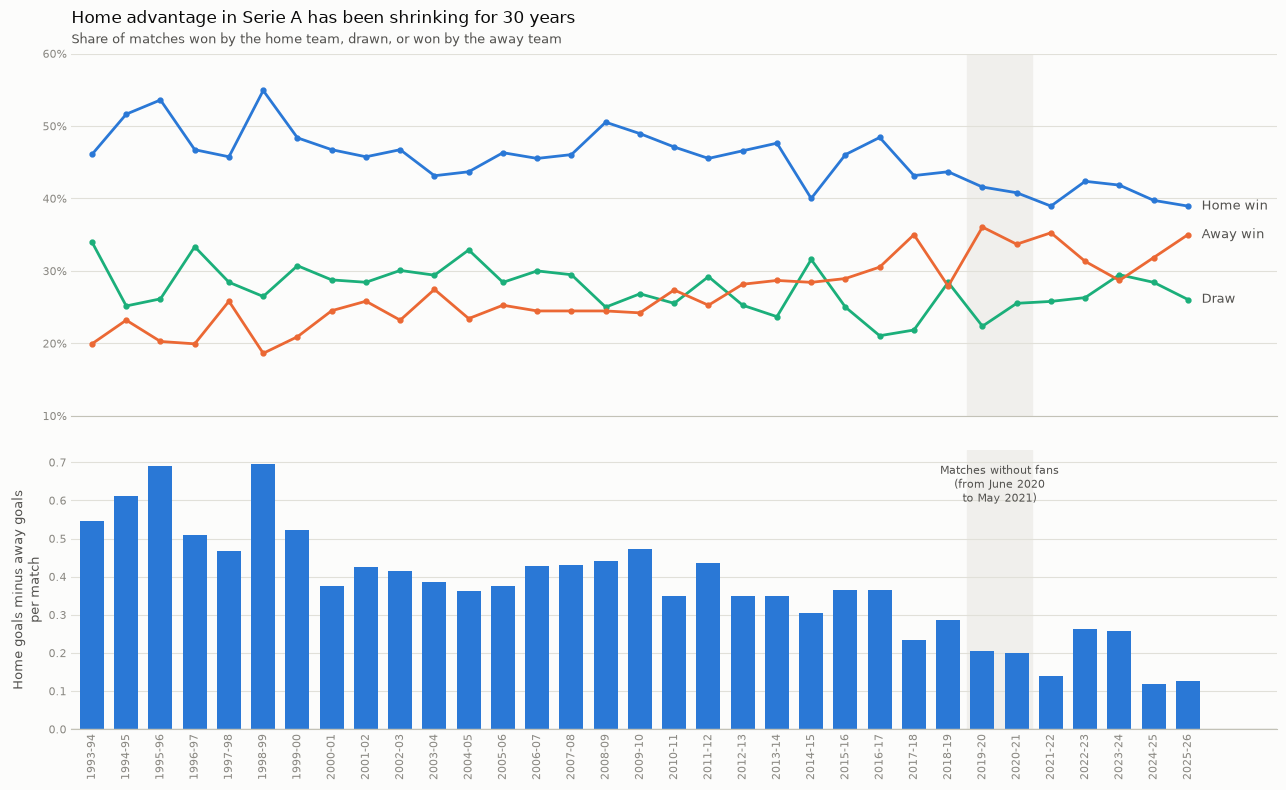

In [23]:
fig, (ax_share, ax_gd) = plt.subplots(
    2, 1, figsize=(13, 8), facecolor=SURFACE, sharex=True, gridspec_kw={"height_ratios": [1.3, 1]}
)
x = np.arange(len(seasons))
closed_doors = [seasons.index(s) for s in ("2019-20", "2020-21")]

# Top: result shares per season, labelled directly at the line ends
for outcome, column in zip(OUTCOMES, ["home_win", "draw", "away_win"]):
    values = by_season[column].values
    ax_share.plot(x, values, color=OUTCOME_COLORS[outcome], linewidth=2, marker="o", markersize=3.5)
    ax_share.text(x[-1] + 0.4, values[-1], OUTCOME_LABELS[outcome], va="center", fontsize=9,
                  color=INK_2)
ax_share.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax_share.set_ylim(0.1, 0.6)
style_axes(ax_share)
set_title(ax_share, "Home advantage in Serie A has been shrinking for 30 years",
          "Share of matches won by the home team, drawn, or won by the away team")

# Bottom: average home goal difference per season
ax_gd.bar(x, by_season["home_goal_diff"].values, color=BLUE, width=0.7)
ax_gd.axhline(0, color=BASELINE, linewidth=1)
ax_gd.set_ylabel("Home goals minus away goals\nper match", color=INK_2, fontsize=9)
style_axes(ax_gd)

for ax in (ax_share, ax_gd):
    ax.axvspan(closed_doors[0] - 0.45, closed_doors[1] + 0.45, color=SHADE, zorder=0)
ax_gd.text(np.mean(closed_doors), by_season["home_goal_diff"].max(),
           "Matches without fans\n(from June 2020\nto May 2021)",
           ha="center", va="top", fontsize=8, color=INK_2)

season_axis(ax_gd)
ax_share.set_xlim(-0.6, len(seasons) + 1.6)  # room for the line labels
fig.tight_layout(h_pad=2)
save_figure(fig, "04_home_advantage_by_season.png")
plt.show()

**Interpretation**

- Home advantage has **declined steadily**. In the 1990s home teams won about half of their
  matches and scored about 0.58 more goals per match than visitors. Over the last five seasons the
  home-win share is about 40%, and the goal edge has fallen to under 0.2.
- Away wins have risen from roughly 1 in 5 matches to about 1 in 3.
- The matches played without fans (2020-21) had low home advantage, but the decline was
  already under way before COVID and has **not recovered** since fans returned. Empty stadiums
  were not the main cause.
- **For modelling:** home advantage is not a constant. A model trained mostly on older seasons
  would overrate home teams. Recent seasons should carry more weight, or the model needs a way
  to adapt over time, and evaluation should be done on the most recent seasons.

### 6.4 Competitive balance: how unequal is the league?

To compare teams across the whole league, each match is split into two rows, one per team.
Each row records the points that team earned: 3 for a win, 1 for a draw. The **spread
(standard deviation) of points per game** across all teams in a season measures how unequal
the league is. A higher spread means a bigger gap between strong and weak teams, which should
make results easier to predict.

*Note: points are computed from results only, at 3 points per win for every season (1993-94
actually awarded 2), so official tables with points deductions can differ slightly.*

In [24]:
def team_matches(frame):
    """One row per team per match: each match appears once for each side."""
    sides = []
    for side, other in (("home", "away"), ("away", "home")):
        sides.append(pd.DataFrame({
            "season": frame["season"],
            "team": frame[f"{side}_team"],
            "goals_for": frame[f"{side}_goals"],
            "goals_against": frame[f"{other}_goals"],
        }))
    rows = pd.concat(sides, ignore_index=True)
    rows["points"] = np.select(
        [rows["goals_for"] > rows["goals_against"], rows["goals_for"] == rows["goals_against"]],
        [3, 1], default=0,
    )
    return rows


team_seasons = (team_matches(completed)
                .groupby(["season", "team"])["points"].mean()
                .rename("points_per_game").reset_index())
balance = team_seasons.groupby("season")["points_per_game"].agg(["std", "max", "min"]).reindex(seasons)
balance["rolling_5"] = balance["std"].rolling(5, min_periods=3).mean()

print(f"Spread of points per game, 1990s average: "
      f"{balance.loc[seasons[:7], 'std'].mean():.2f} | since 2016-17: "
      f"{balance.loc['2016-17':, 'std'].mean():.2f}")

Spread of points per game, 1990s average: 0.41 | since 2016-17: 0.50


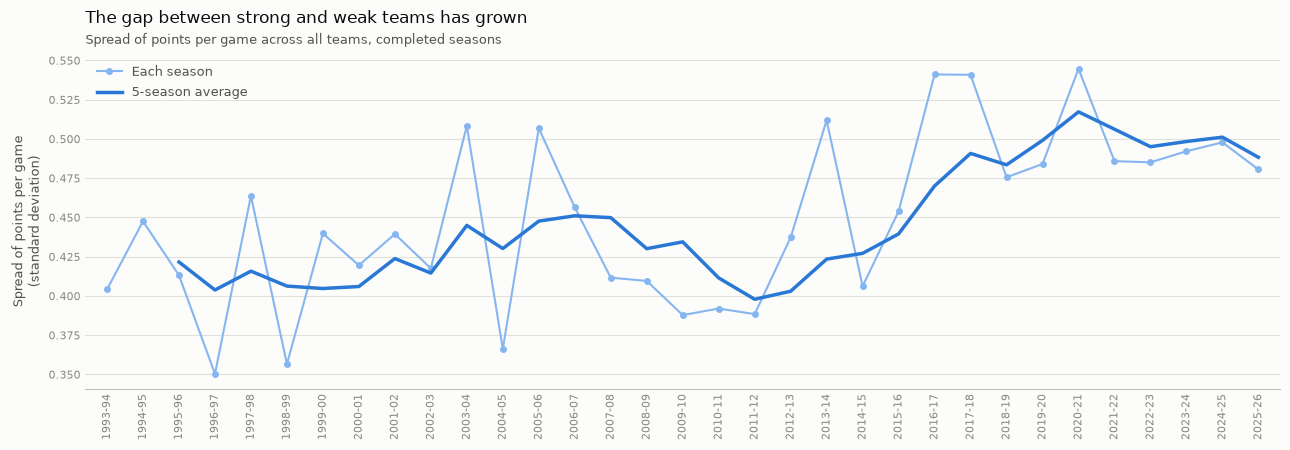

In [25]:
fig, ax = plt.subplots(figsize=(13, 4.6), facecolor=SURFACE)
x = np.arange(len(seasons))
ax.plot(x, balance["std"].values, color=BLUE_LIGHT, linewidth=1.5, marker="o", markersize=4,
        label="Each season")
ax.plot(x, balance["rolling_5"].values, color=BLUE, linewidth=2.5, label="5-season average")
ax.set_ylabel("Spread of points per game\n(standard deviation)", color=INK_2, fontsize=9)
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="upper left")
season_axis(ax)
style_axes(ax)
set_title(ax, "The gap between strong and weak teams has grown",
          "Spread of points per game across all teams, completed seasons")
fig.tight_layout()
save_figure(fig, "05_competitive_balance.png")
plt.show()

**Interpretation**

- The spread of points per game has risen from about **0.41** in the 1990s to about **0.50**
  since 2016-17, so Serie A has become **more unequal**. The best teams collect more points and
  the weakest collect fewer.
- This is not caused by the switch from 34-game to 38-game seasons in 2004-05. Shorter seasons
  produce *noisier* points-per-game values, which would inflate the 1990s spread, so the real
  increase is if anything slightly larger.
- Together with 6.3, this suggests that **team strength now matters more than playing at home**.
  Features describing how good each team is should carry most of the predictive power: recent
  form, goals scored and conceded, points per game, and the bookmakers' odds.

### Key findings

| Finding | What it means for the model |
|---|---|
| Home win 45%, draw 27%, away win 27% | Baseline to beat: about 45% accuracy by always predicting a home win |
| Draws are frequent but have no clear favourite | Expect the draw class to be the hardest to predict |
| Goals per match are close to Poisson | Goal-scoring rates are sensible features |
| Home advantage has roughly halved since the 1990s | Weight recent seasons; test on the most recent seasons |
| The league has become more unequal | Team-strength features should matter most |
| Statistics from 2005-06, odds from 2002-03 (section 4) | Results-only features can use all seasons; statistics-based features cannot |

## Next steps

- **Commit 5: feature engineering.** Build per-team features (recent form, goals scored and
  conceded, points per game, home and away records), using **only matches played before each
  game** so the model never sees the future.
- **Commit 6:** a first Logistic Regression model, evaluated against the 45% "always home win"
  baseline on the most recent seasons.
- Later notebooks load this dataset with `src.preprocessing.load_matches()`, which restores the
  correct column types.